<a href="https://colab.research.google.com/github/pauloricardodomingues21-byte/Tech-Challenge-Fase-1/blob/main/notebooks/CSV_modelo_nps_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tech Challenge Fase 1 - Modelo preditivo de NPS

**Passo 1:** rode a celula abaixo e escolha o arquivo CSV.
**Passo 2:** rode a celula do modelo.
**Passo 3:** rode a ultima celula para ver o grafico.

In [ ]:
from google.colab import files
up = files.upload()
NOME_CSV = list(up.keys())[0]
print('Arquivo carregado:', NOME_CSV)

Saving base_nps_teste.csv to base_nps_teste.csv
Arquivo carregado: base_nps_teste.csv


## Codigo do modelo

In [ ]:
"""
Tech Challenge Fase 1 - Modelo preditivo de NPS

Uso:
    python treino_modelo_nps.py caminho/para/base_nps.csv

Gera:
    models/modelo_regressao.joblib
    models/modelo_classificacao.joblib
    reports/importancia_variaveis.png
    reports/metricas.txt
"""
import sys
from pathlib import Path

import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error,
                             r2_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
ALVO = "nps_score"

# Variaveis removidas para evitar vazamento de dados (data leakage):
# - csat_internal_score: medida de satisfacao coletada junto/apos a experiencia
# - repeat_purchase_30d: acontece DEPOIS do pedido (consequencia, nao causa)
# - ids: nao tem poder preditivo generalizavel
REMOVER = ["customer_id", "order_id", "csat_internal_score", "repeat_purchase_30d"]

# Classificacao no padrao NPS: detrator = nota 0 a 6
LIMITE_DETRATOR = 6


def carregar_dados(caminho):
    df = pd.read_csv(caminho)
    df = df.drop_duplicates()
    df = df.dropna(subset=[ALVO])           # sem alvo nao da para treinar
    df = df[df[ALVO].between(0, 10)]        # garante escala valida
    return df


def montar_preprocessador(X):
    colunas_cat = X.select_dtypes(include=["object", "category"]).columns.tolist()
    colunas_num = [c for c in X.columns if c not in colunas_cat]

    num = Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler())])
    cat = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, colunas_num),
                              ("cat", cat, colunas_cat)])


def main(caminho_csv):
    Path("models").mkdir(exist_ok=True)
    Path("reports").mkdir(exist_ok=True)

    df = carregar_dados(caminho_csv)
    colunas_remover = [c for c in REMOVER if c in df.columns]
    X = df.drop(columns=colunas_remover + [ALVO])
    y_reg = df[ALVO]
    y_clf = (df[ALVO] <= LIMITE_DETRATOR).astype(int)  # 1 = detrator

    # Split unico (estratificado pela classe) para comparar os dois modelos
    X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = train_test_split(
        X, y_reg, y_clf, test_size=0.2, random_state=SEED, stratify=y_clf)

    linhas = [f"Linhas: {len(df)} | Detratores: {y_clf.mean():.1%}", ""]

    # ---------------- REGRESSAO ----------------
    base_reg = Pipeline([("prep", montar_preprocessador(X)), ("m", Ridge())])
    gb_reg = Pipeline([("prep", montar_preprocessador(X)),
                       ("m", GradientBoostingRegressor(random_state=SEED))])
    linhas.append("== REGRESSAO (nota 0-10) ==")
    melhor_reg, melhor_mae = None, np.inf
    for nome, pipe in [("Ridge (baseline)", base_reg), ("GradientBoosting", gb_reg)]:
        pipe.fit(X_tr, yr_tr)
        p = pipe.predict(X_te)
        mae = mean_absolute_error(yr_te, p)
        rmse = np.sqrt(mean_squared_error(yr_te, p))
        linhas.append(f"{nome}: MAE={mae:.2f} RMSE={rmse:.2f} R2={r2_score(yr_te, p):.3f}")
        if mae < melhor_mae:
            melhor_reg, melhor_mae = pipe, mae
    linhas.append(f"Referencia ingenua (prever a media): MAE="
                  f"{mean_absolute_error(yr_te, np.full(len(yr_te), yr_tr.mean())):.2f}\n")

    # ---------------- CLASSIFICACAO ----------------
    base_clf = Pipeline([("prep", montar_preprocessador(X)),
                         ("m", LogisticRegression(max_iter=1000, class_weight="balanced"))])
    gb_clf = Pipeline([("prep", montar_preprocessador(X)),
                       ("m", GradientBoostingClassifier(random_state=SEED))])
    linhas.append("== CLASSIFICACAO (detrator vs nao detrator) ==")
    melhor_clf, melhor_auc = None, -1
    for nome, pipe in [("Logistica (baseline)", base_clf), ("GradientBoosting", gb_clf)]:
        pipe.fit(X_tr, yc_tr)
        proba = pipe.predict_proba(X_te)[:, 1]
        auc = roc_auc_score(yc_te, proba)
        linhas.append(f"{nome}: ROC-AUC={auc:.3f}")
        if auc > melhor_auc:
            melhor_clf, melhor_auc = pipe, auc

    # Limiar de decisao: priorizamos recall de detratores (melhor errar
    # por excesso de alerta do que deixar um detrator passar). Ajuste conforme
    # a capacidade do time de atendimento.
    proba = melhor_clf.predict_proba(X_te)[:, 1]
    pred = (proba >= 0.4).astype(int)
    linhas.append("\nLimiar = 0.40")
    linhas.append("Matriz de confusao [[VN FP],[FN VP]]:")
    linhas.append(str(confusion_matrix(yc_te, pred)))
    linhas.append(classification_report(yc_te, pred, target_names=["nao detrator", "detrator"]))

    # ---------------- IMPORTANCIA DAS VARIAVEIS ----------------
    imp = permutation_importance(melhor_clf, X_te, yc_te, scoring="roc_auc",
                                 n_repeats=10, random_state=SEED)
    serie = pd.Series(imp.importances_mean, index=X.columns).sort_values()
    serie.plot(kind="barh", figsize=(8, 6), color="#1f77b4")
    plt.title("Importancia das variaveis (queda no ROC-AUC ao embaralhar)")
    plt.tight_layout()
    plt.savefig("reports/importancia_variaveis.png", dpi=150)
    linhas.append("\nTop 5 variaveis:\n" + serie.sort_values(ascending=False).head(5).to_string())

    joblib.dump(melhor_reg, "models/modelo_regressao.joblib")
    joblib.dump(melhor_clf, "models/modelo_classificacao.joblib")
    Path("reports/metricas.txt").write_text("\n".join(linhas), encoding="utf-8")
    print("\n".join(linhas))


In [ ]:
main(NOME_CSV)

Linhas: 5000 | Detratores: 24.2%

== REGRESSAO (nota 0-10) ==
Ridge (baseline): MAE=0.90 RMSE=1.13 R2=0.289
GradientBoosting: MAE=0.92 RMSE=1.15 R2=0.264
Referencia ingenua (prever a media): MAE=1.11

== CLASSIFICACAO (detrator vs nao detrator) ==
Logistica (baseline): ROC-AUC=0.783
GradientBoosting: ROC-AUC=0.763

Limiar = 0.40
Matriz de confusao [[VN FP],[FN VP]]:
[[465 293]
 [ 41 201]]
              precision    recall  f1-score   support

nao detrator       0.92      0.61      0.74       758
    detrator       0.41      0.83      0.55       242

    accuracy                           0.67      1000
   macro avg       0.66      0.72      0.64      1000
weighted avg       0.80      0.67      0.69      1000


Top 5 variaveis:
delivery_delay_days     0.162502
resolution_time_days    0.096078
complaints_count        0.027587
delivery_attempts       0.015392
customer_region         0.000377


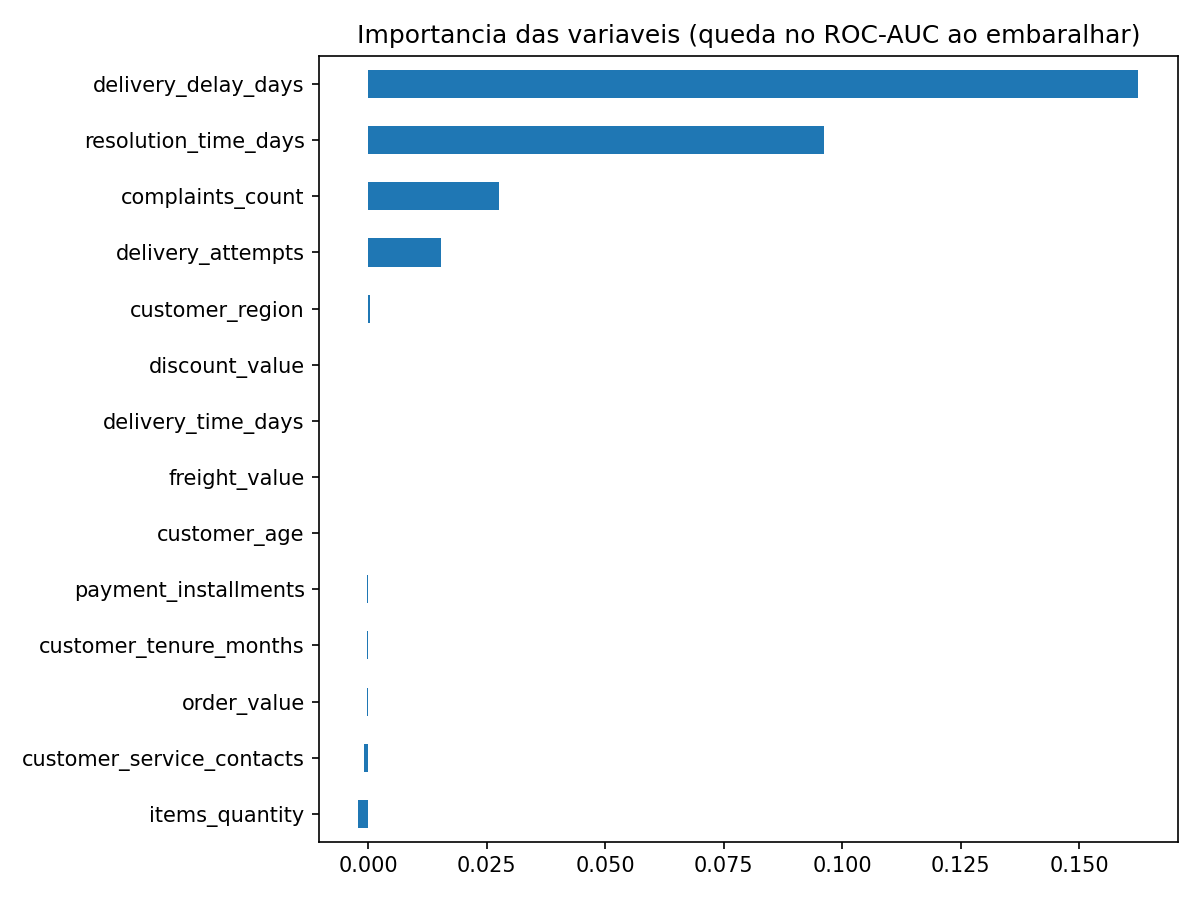

In [ ]:
from IPython.display import Image
Image('reports/importancia_variaveis.png')